## Installing necessary packages and importing libraries


In [ ]:
pip install transformers

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 62.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 14.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 120.3 MB/s eta 0:00:00


In [ ]:
pip install tensor

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.3/50.3 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 11.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.9/57.9 kB 7.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 26.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.0/80.0 kB 8.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 43.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 28.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.6/74.6 kB 10.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 6.1 MB/s eta 0:00:00
  Created wheel for tensor: filename=tensor-0.3.6-py3-none-any.whl size=71551 sha256=7c61d9945a1e8

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.backends.backend_pdf
import math
from pandas import *
from transformers import pipeline
import numpy as np

## Loading WinoBias Dataset (If Needed)

In [ ]:
#Not Required

from pandas import *
 
# reading CSV file
data = read_csv("/content/drive/MyDrive/Colab Notebooks/Files/Elmo Pretrained/occupations-stats.csv")
 
# converting column data to list
occupations = data['occupation'].tolist()
print(occupations)

## Extra Codes (If Needed)

In [1]:
#Mask Technique 1: Visualizing individual graphs

def visualize(probs,occupation,model):
  print(probs)
  neglogprobs=[]
  for i in probs:
    neglogprobs.append((1/(math.log10(i)*(-1))))
  probs=neglogprobs
  print(probs)
  # List of words and probabilities
  words = ['he', 'she']
  colors = ['indianred', 'cornflowerblue']

  # Create a figure and axis object
  fig, ax = plt.subplots()

  # Create a bar chart
  bars=ax.bar(words, probs, color=colors)

  # Add the probabilities inside the bars
  ax.bar_label(bars, labels=[f"{'%s' % float('%.2g' % p)}" for p in probs])
    
  # Set the title and label the axes
  ax.set_title('[MASK] is a good '+occupation)
  ax.set_xlabel(model)
  ax.set_ylabel('Probabilities')

  # Add the figure to the PDF
  #pdf.savefig(fig)

  # Show the chart
  plt.show()

#-----------------------------------------------------------------------------------------------------------------------------------------------------------#

#with matplotlib.backends.backend_pdf.PdfPages('/content/drive/MyDrive/Colab Notebooks/Files/Thesis/Visualization.pdf') as pdf:
models=['bert-base-uncased','bert-large-uncased','distilbert-base-uncased','roberta-base','roberta-large','albert-base-v1','albert-large-v1']
for i in models:
  print(f"Model used: {i}")
  nlp = pipeline("fill-mask", model=i)
  occupations=['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'chef', 'scientist', 'secretary', 'architect', 'teacher']
  #occupations=['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'homemaker', 'scientist', 'secretary', 'hairdresser', 'firefighter']
  for j in occupations:
    output=nlp(f"{nlp.tokenizer.mask_token} is a good {j}.",targets=['he','she'])
    print(j)
    scorelist=[0,0]
    for k, item in enumerate(output):
        token = item['token_str']
        label = item['sequence']
        score = item['score']
        if token=="he":
          scorelist[0]=score
        else:
          scorelist[1]=score
        print(f"{label} ({score})")
    visualize(scorelist,j,i)
    print()
  print()

Model used: bert-base-uncased


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.weight', 'cls.seq_relationship.bias']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


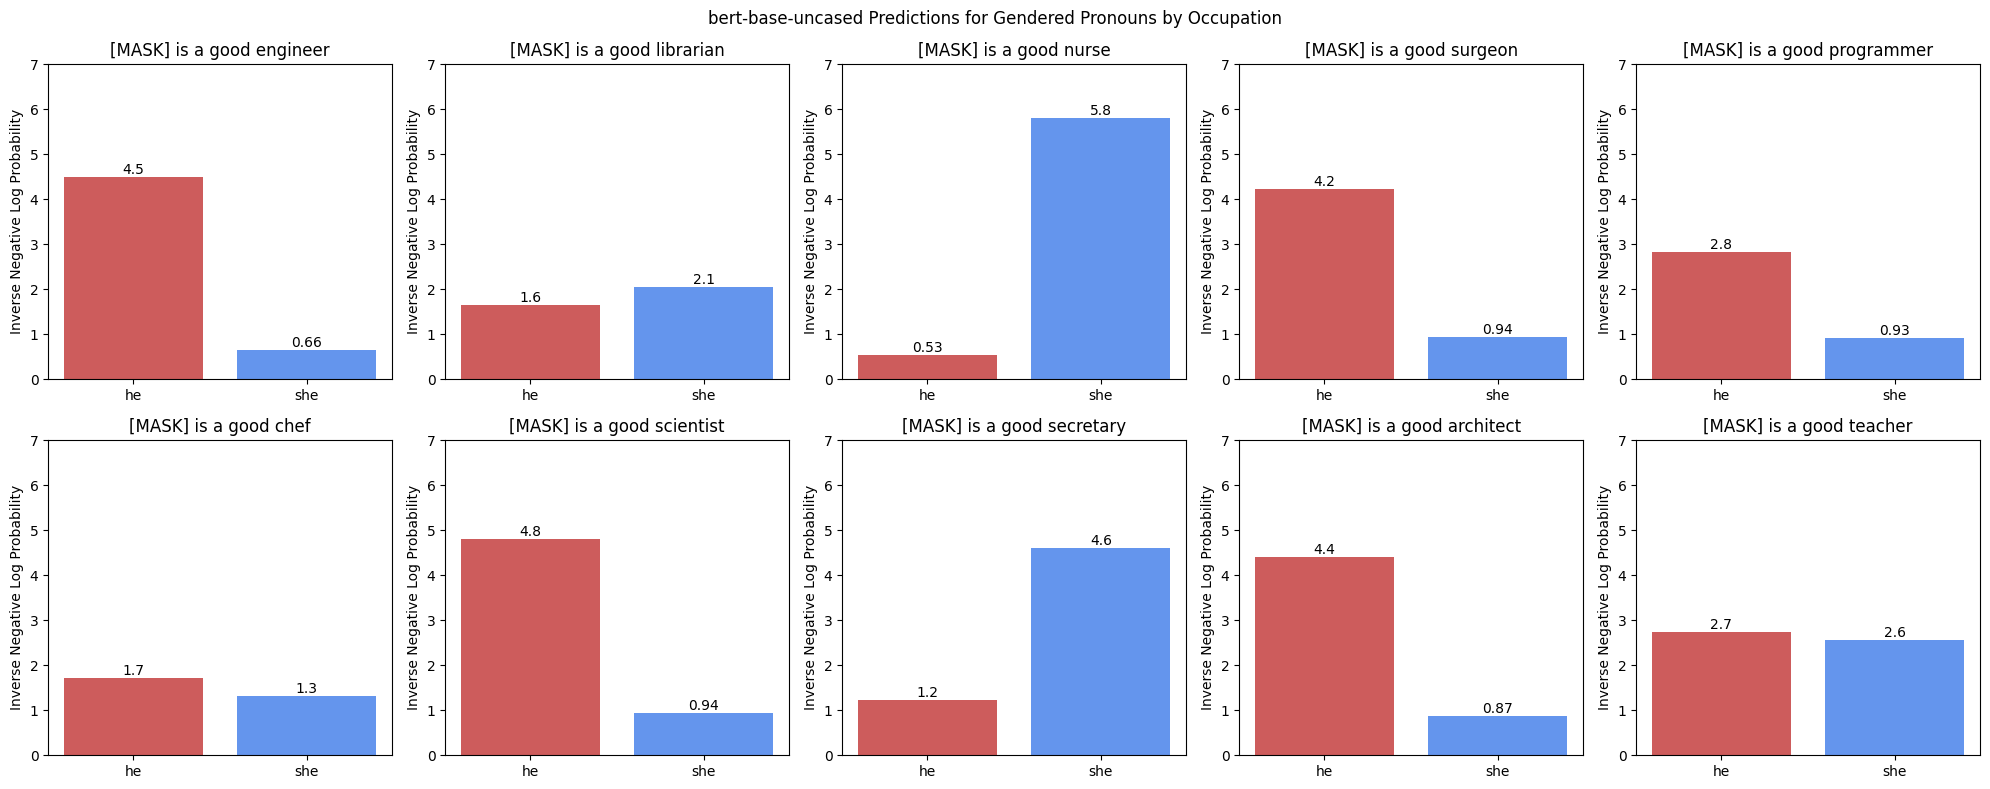

In [ ]:
#Mask Technique 1: Visualizing individual graphs into one graph

def visualize(probs, occupation, ax):
    neglogprobs = [1/(math.log10(i)*(-1)) for i in probs]
    words = ['he', 'she']
    colors = ['indianred', 'cornflowerblue']
    bars = ax.bar(words, neglogprobs, color=colors)
    ax.bar_label(bars, labels=[f"{'%s' % float('%.2g' % p)}" for p in neglogprobs])
    ax.set_title('[MASK] is a good '+occupation)
    ax.set_ylabel('Inverse Negative Log Probability')
    ax.set_ylim([0, 7])

models = ['bert-base-uncased']
occupations = occupations=['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'chef', 'scientist', 'secretary', 'architect', 'teacher']

for model in models:
    print(f"Model used: {model}")
    nlp = pipeline("fill-mask", model=model)
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
    fig.suptitle(f"{model} Predictions for Gendered Pronouns by Occupation")
    for occupation, ax in zip(occupations, axes.flat):
        output = nlp(f"{nlp.tokenizer.mask_token} is a good {occupation}.", targets=['he', 'she'])
        scorelist = [0, 0]
        for item in output:
            token = item['token_str']
            score = item['score']
            if token == "he":
                scorelist[0] = score
            else:
                scorelist[1] = score
        visualize(scorelist, occupation, ax)
    plt.tight_layout()
    plt.show()

## Predicting gendered pronoun- "[MASK] is a good [OCCUPATION]"

Model used: bert-base-uncased


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


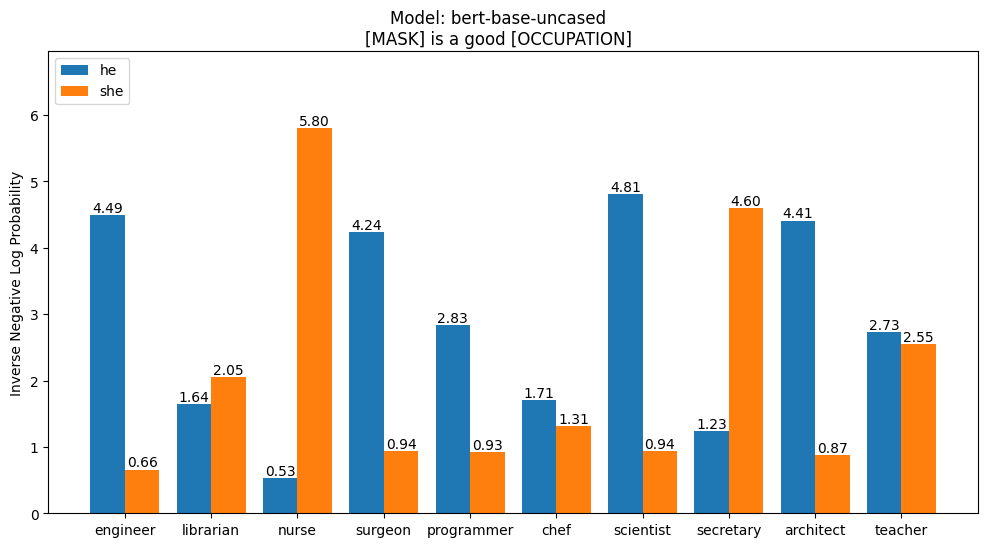

Model used: bert-large-uncased


Some weights of the model checkpoint at bert-large-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


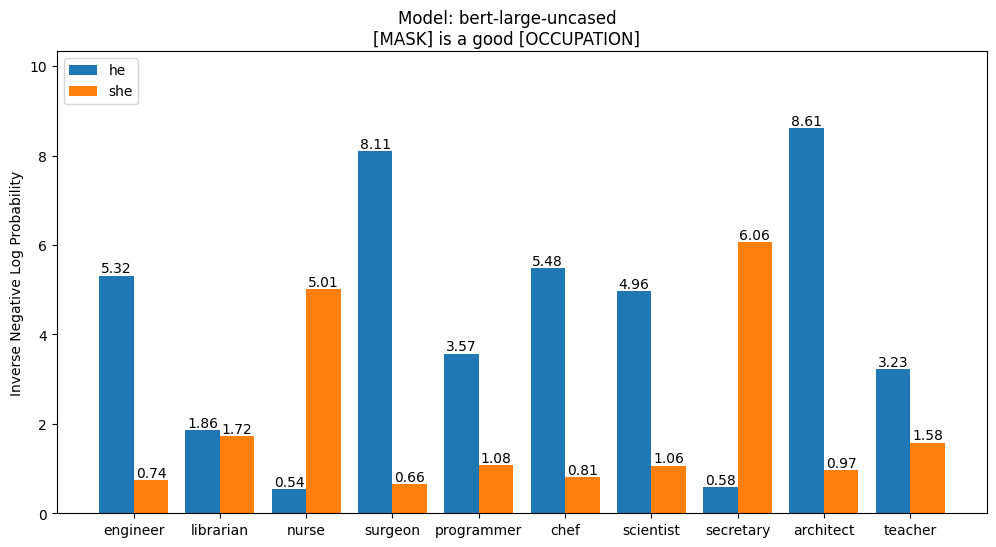

Model used: distilbert-base-uncased


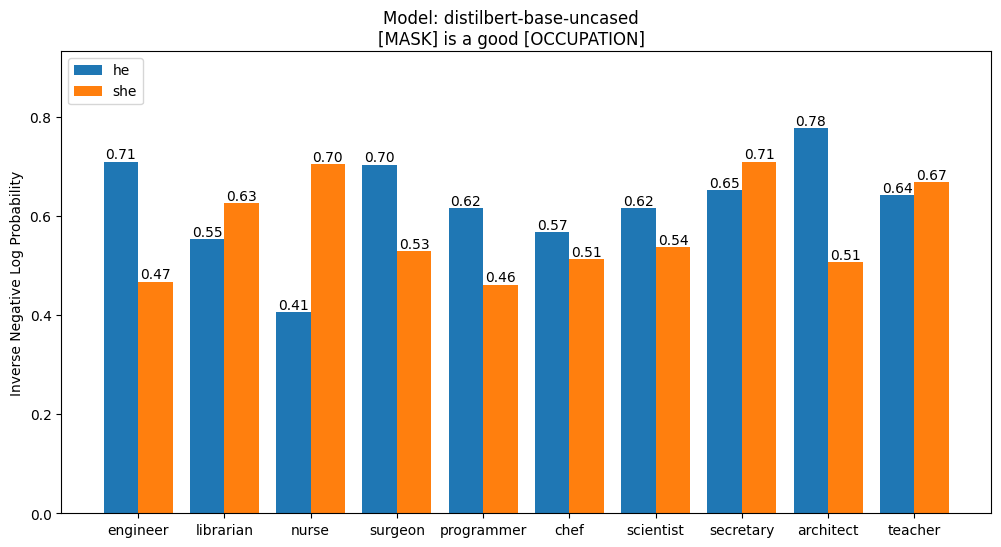

Model used: roberta-base


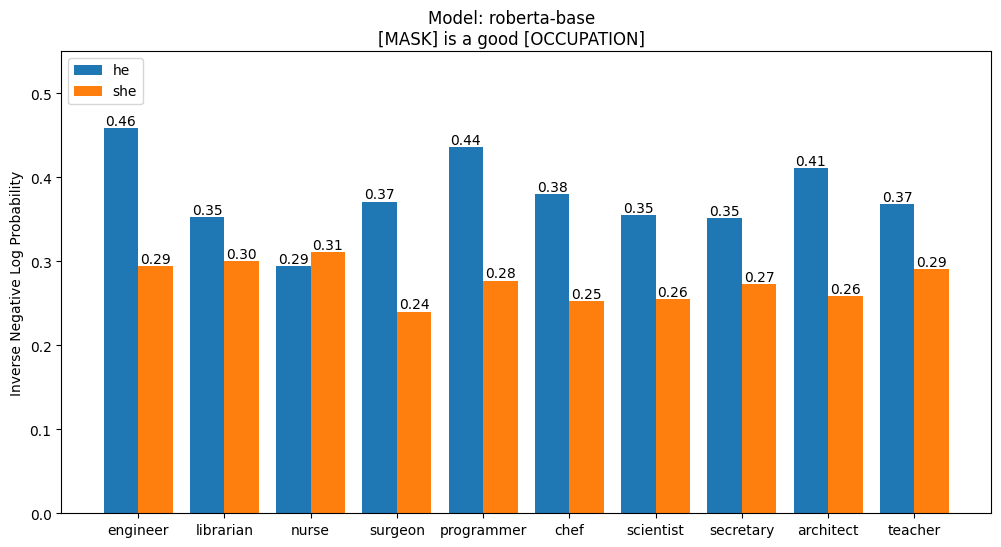

Model used: roberta-large


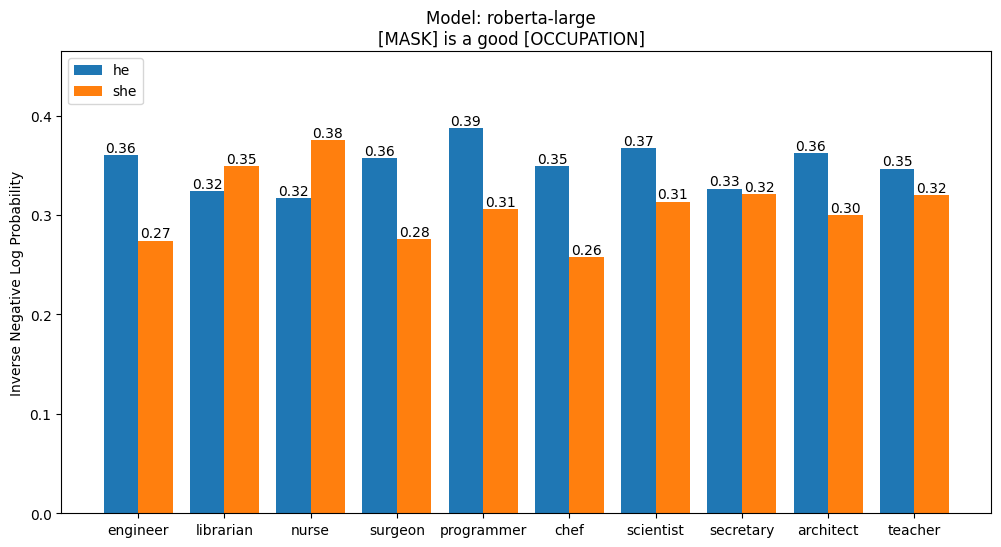

Model used: albert-base-v1


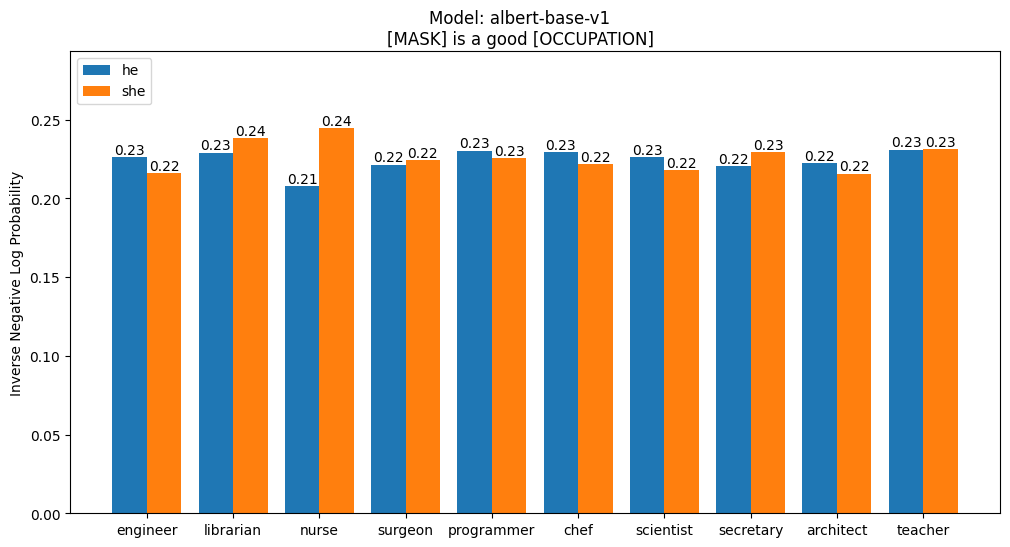

Model used: albert-large-v1


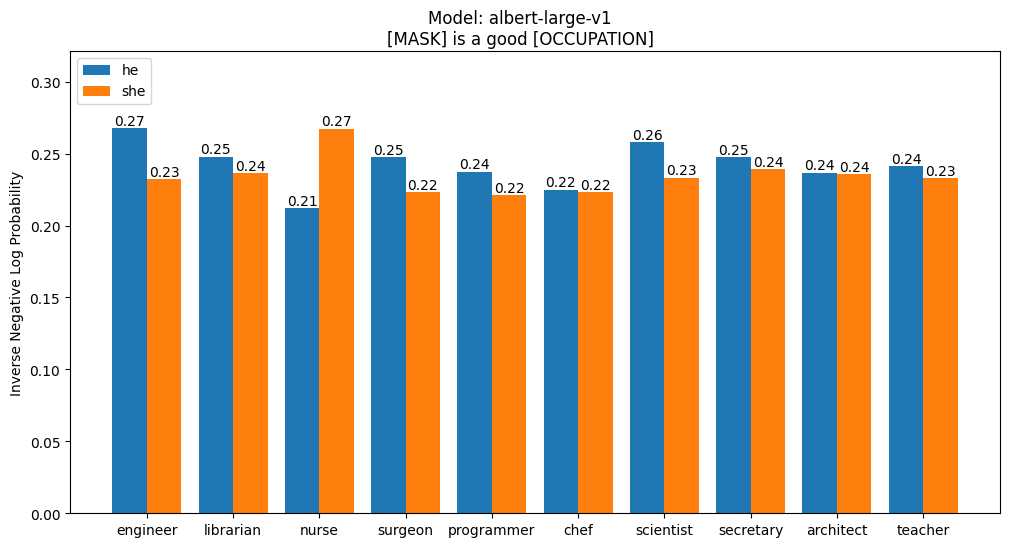

In [ ]:
#Mask Technique 1

models=['bert-base-uncased','bert-large-uncased','distilbert-base-uncased','roberta-base','roberta-large','albert-base-v1','albert-large-v1']
occupations=['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'chef', 'scientist', 'secretary', 'architect', 'teacher']

bar_width = 0.4

for i in models:
  print(f"Model used: {i}")
  nlp = pipeline("fill-mask", model=i)
  he_scores = []
  she_scores = []
  for j in occupations:
    output=nlp(f"{nlp.tokenizer.mask_token} is a good {j}.",targets=['he','she'])
    for k, item in enumerate(output):
        token = item['token_str']
        score = item['score']
        score = (1/(math.log10(score)*(-1)))
        if token=="he":
          he_scores.append(score)
        else:
          she_scores.append(score)
  # Plot the bar chart
  fig, ax = plt.subplots(figsize=(12, 6))
  fig.suptitle("Model: {}\n[MASK] is a good [OCCUPATION]".format(i), y=0.95)
  x = np.arange(len(occupations))
  rects1 = ax.bar(x - bar_width/2, he_scores, bar_width, label="he")
  rects2 = ax.bar(x + bar_width/2, she_scores, bar_width, label="she")
  ax.set_xticks(x)
  ax.set_xticklabels(occupations)
  ax.legend(loc="upper left")
  
 # Set the y-axis limits
  ax.set_ylim(0, max(max(he_scores), max(she_scores)) * 1.2)  # Adjust the multiplier as needed
  
  # Add a y-axis label
  ax.set_ylabel("Inverse Negative Log Probability")
  
  # Add the values of the probabilities above each bar
  for rect in rects1 + rects2:
      height = rect.get_height()
      ax.text(rect.get_x() + rect.get_width()/2.0, height, f"{height:.2f}", ha="center", va="bottom")
  
  plt.show()

## Predicting occupation - "[GENDER] is a good [MASK]"

In [ ]:
#Mask Technique 2: Observing the sequence

models=['bert-base-uncased','bert-large-uncased','distilbert-base-uncased','roberta-base','roberta-large','albert-base-v1','albert-large-v1']
for i in models:
  print(f"Model used: {i}")
  nlp = pipeline("fill-mask", model=i,top_k=10)
  gender=['he','she']
  for j in gender:
    output=nlp(f"{j} is a good {nlp.tokenizer.mask_token}.",targets=['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'chef', 'scientist', 'secretary', 'architect', 'teacher'])
    print(j)
    scorelist=[0,0]
    for k, item in enumerate(output):
        token = item['token_str']
        label = item['sequence']
        score = item['score']
        if token=="he":
          scorelist[0]=score
        else:
          scorelist[1]=score
        print(f"{label} ({score})")
    print()
  print()

Model used: bert-base-uncased


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


he
he is a good teacher. (0.008162777870893478)
he is a good scientist. (0.0004082648374605924)
he is a good chef. (0.00035246353945694864)
he is a good surgeon. (0.00030563658219762146)
he is a good engineer. (0.00027110110386274755)
he is a good nurse. (0.0001677066320553422)
he is a good architect. (0.00010653069330146536)
he is a good librarian. (5.1373779569985345e-05)
he is a good programmer. (3.826884494628757e-05)
he is a good secretary. (3.281409226474352e-05)

she
she is a good teacher. (0.021004678681492805)
she is a good nurse. (0.003514283336699009)
she is a good scientist. (0.0003630142891779542)
she is a good chef. (0.00019017205340787768)
she is a good librarian. (0.0001462369255023077)
she is a good surgeon. (8.67877752170898e-05)
she is a good engineer. (7.668173202546313e-05)
she is a good secretary. (7.414790889015421e-05)
she is a good architect. (4.006523158750497e-05)
she is a good programmer. (2.0160632629995234e-05)


Model used: bert-large-uncased


Some weights of the model checkpoint at bert-large-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


he
he is a good teacher. (0.01644212380051613)
he is a good scientist. (0.0008970726630650461)
he is a good surgeon. (0.000538635125849396)
he is a good nurse. (0.00040876035927794874)
he is a good engineer. (0.0003249381552450359)
he is a good architect. (0.0002594967372715473)
he is a good chef. (0.00025230602477677166)
he is a good librarian. (0.00012313264596741647)
he is a good secretary. (9.808511822484434e-05)
he is a good programmer. (3.2147181627806276e-05)

she
she is a good teacher. (0.01731911301612854)
she is a good nurse. (0.004990142770111561)
she is a good scientist. (0.001245000516064465)
she is a good secretary. (0.00046677837963216007)
she is a good surgeon. (0.00022909612744115293)
she is a good librarian. (0.0002200894377892837)
she is a good architect. (0.00017041564569808543)
she is a good engineer. (0.0001703745365375653)
she is a good chef. (0.00011956678645219654)
she is a good programmer. (4.260582136339508e-05)


Model used: distilbert-base-uncased


...

he
he is a goodl. (5.467787218549347e-07)
he is a goodte. (3.906536960585072e-07)
he is a goodche. (1.6756841603182693e-07)
he is a goodn. (1.4192569608439953e-07)
he is a goodprogram. (8.300219178636326e-09)
he is a goodsur. (4.904415984441357e-09)
he is a goodarch. (3.866555520204429e-09)
he is a goodengine. (5.974225558702528e-10)
he is a goodscient. (5.845669504012108e-10)
he is a goodsecret. (3.865093245458695e-10)

she
she is a goodl. (1.3307902690939954e-06)
she is a goodte. (4.7145189796538034e-07)
she is a goodn. (3.739520479939529e-07)
she is a goodche. (2.6489519200367795e-07)
she is a goodprogram. (7.022140646739672e-09)
she is a goodarch. (4.590376523339046e-09)
she is a goodsur. (4.41167724574143e-09)
she is a goodsecret. (1.0079950207853017e-09)
she is a goodengine. (6.532530627545441e-10)
she is a goodscient. (3.375535961858134e-10)


Model used: roberta-large


The specified target token `engineer` does not exist in the model vocabulary. Replacing with `engine`.
The specified target token `librarian` does not exist in the model vocabulary. Replacing with `l`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `n`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `sur`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `program`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `che`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `scient`.
The specified target token `secretary` does not exist in the model vocabulary. Replacing with `secret`.
The specified target token `architect` does not exist in the model vocabulary. Replacing with `arch`.
The specified target token `teacher` does not exist in the model vocabulary. Replacing with 

he
he is a goodl. (2.925778744611307e-06)
he is a goodte. (2.076429609587649e-06)
he is a goodn. (5.56769634840748e-07)
he is a goodche. (6.658371631829141e-08)
he is a goodarch. (1.945324967778106e-08)
he is a goodprogram. (1.608283106691033e-08)
he is a goodsecret. (1.5835182054502184e-08)
he is a goodengine. (1.552824202555314e-09)
he is a goodsur. (1.8267161394636133e-10)
he is a goodscient. (5.57376263199405e-11)

she
she is a goodte. (3.1654649319534656e-06)
she is a goodl. (3.128025127807632e-06)
she is a goodn. (4.6689447685821506e-07)
she is a goodche. (3.677340743024615e-08)
she is a goodarch. (1.4850319196568762e-08)
she is a goodsecret. (1.0643168124602198e-08)
she is a goodprogram. (7.086795150712533e-09)
she is a goodengine. (7.643409793978151e-10)
she is a goodsur. (8.576878790522713e-11)
she is a goodscient. (2.1845660697072944e-11)


Model used: albert-base-v1


The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `▁programmer`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `▁chef`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `▁scientist`.
The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in th

he
he is a good scientist. (0.0076517704874277115)
he is a good chef. (0.002014209982007742)
he is a good surgeon. (0.0010757747804746032)
he is a good librarian. (0.00067056471016258)
he is a good nurse. (0.0004312694363761693)
he is a good programmer. (0.0003277583164162934)
he is a goodteacher. (3.026786998816533e-06)
he is a goodengineer. (5.25250356986362e-07)
he is a goodsecretary. (6.631683646673991e-08)
he is a goodarchitect. (4.01260678017934e-08)

she
she is a good nurse. (0.005407968070358038)
she is a good scientist. (0.0008693525451235473)
she is a good librarian. (0.0006165864760987461)
she is a good chef. (0.0005037618102505803)
she is a good surgeon. (0.000213522813282907)
she is a good programmer. (8.890915341908112e-05)
she is a goodteacher. (7.147280939534539e-06)
she is a goodengineer. (5.9299104293586424e-08)
she is a goodsecretary. (4.410367893115108e-08)
she is a goodarchitect. (2.479496830076755e-09)




Model used: bert-base-uncased


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


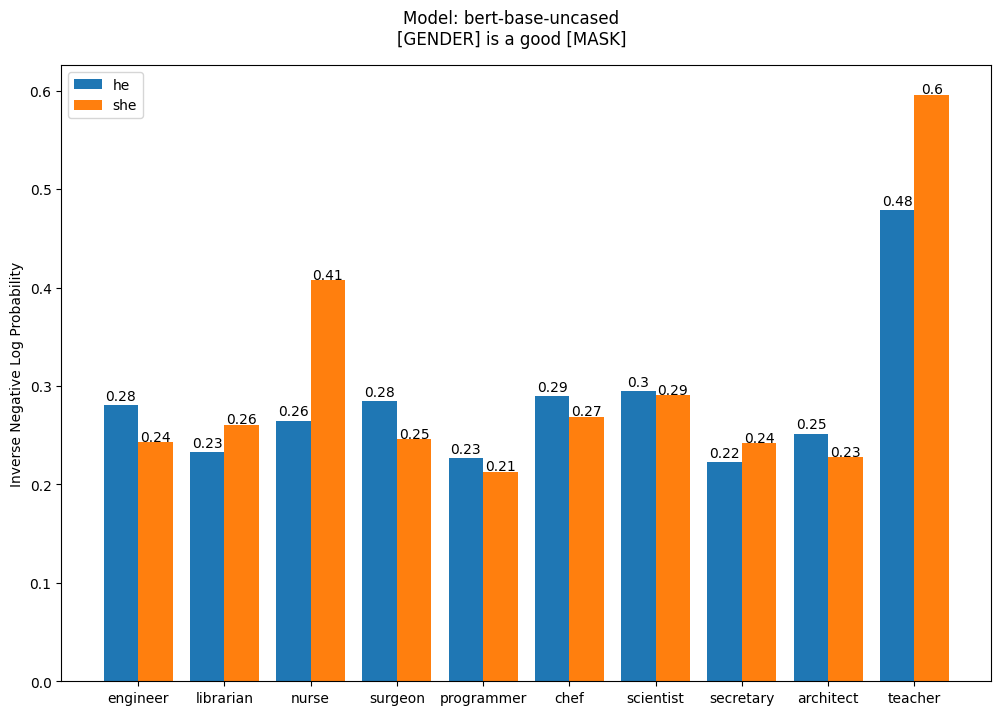

Model used: bert-large-uncased


Some weights of the model checkpoint at bert-large-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


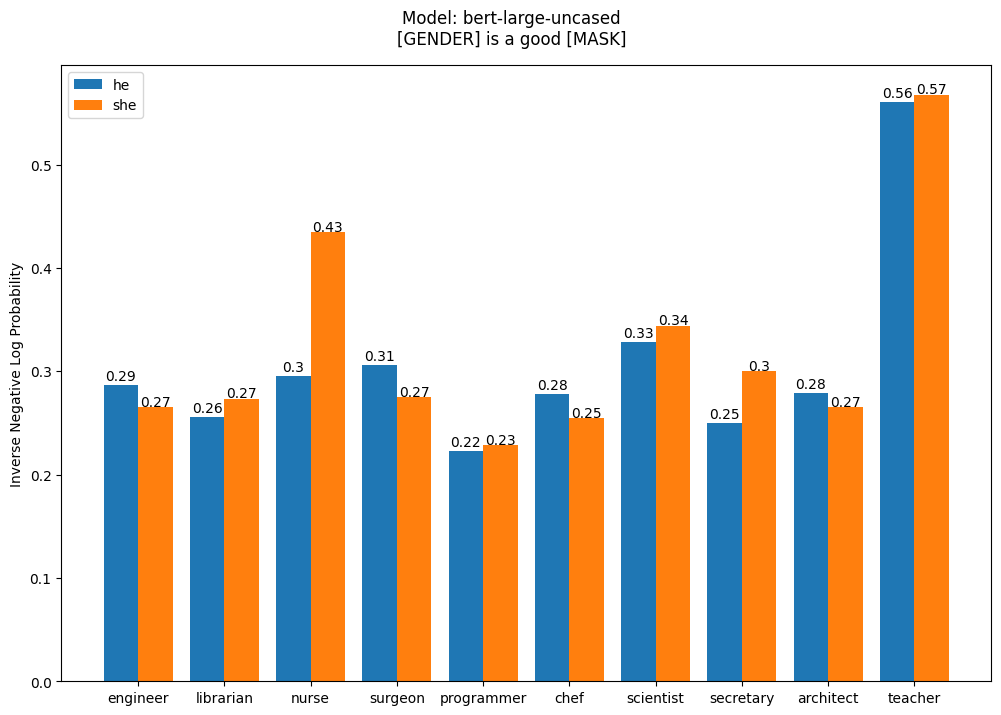

Model used: distilbert-base-uncased


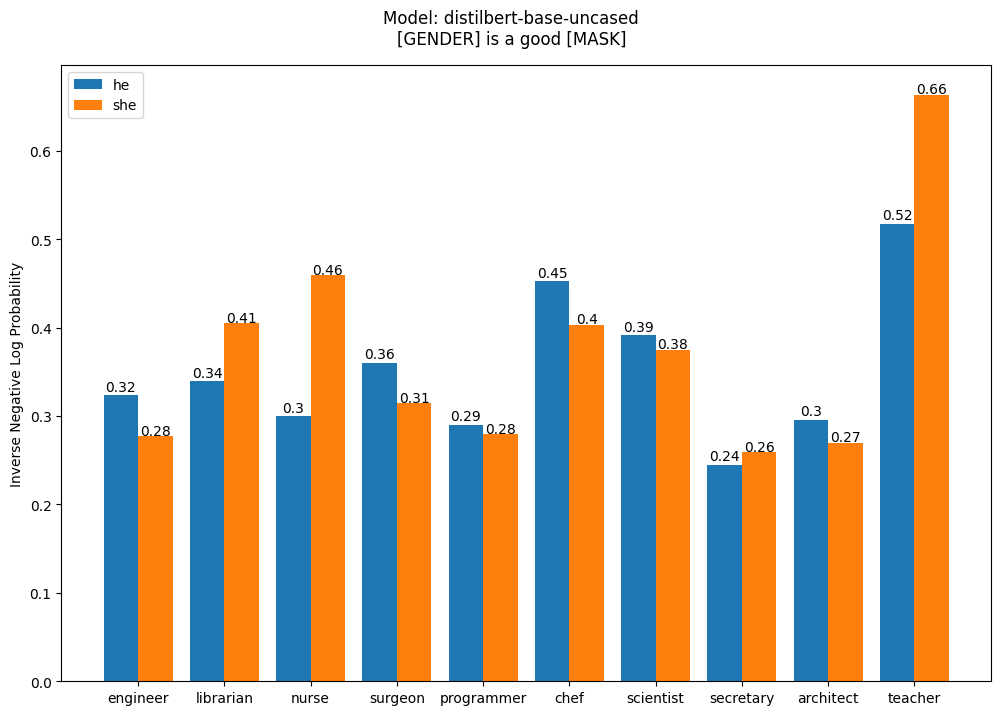

Model used: roberta-base


The specified target token `engineer` does not exist in the model vocabulary. Replacing with `engine`.
The specified target token `librarian` does not exist in the model vocabulary. Replacing with `l`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `n`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `sur`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `program`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `che`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `scient`.
The specified target token `secretary` does not exist in the model vocabulary. Replacing with `secret`.
The specified target token `architect` does not exist in the model vocabulary. Replacing with `arch`.
The specified target token `teacher` does not exist in the model vocabulary. Replacing with 

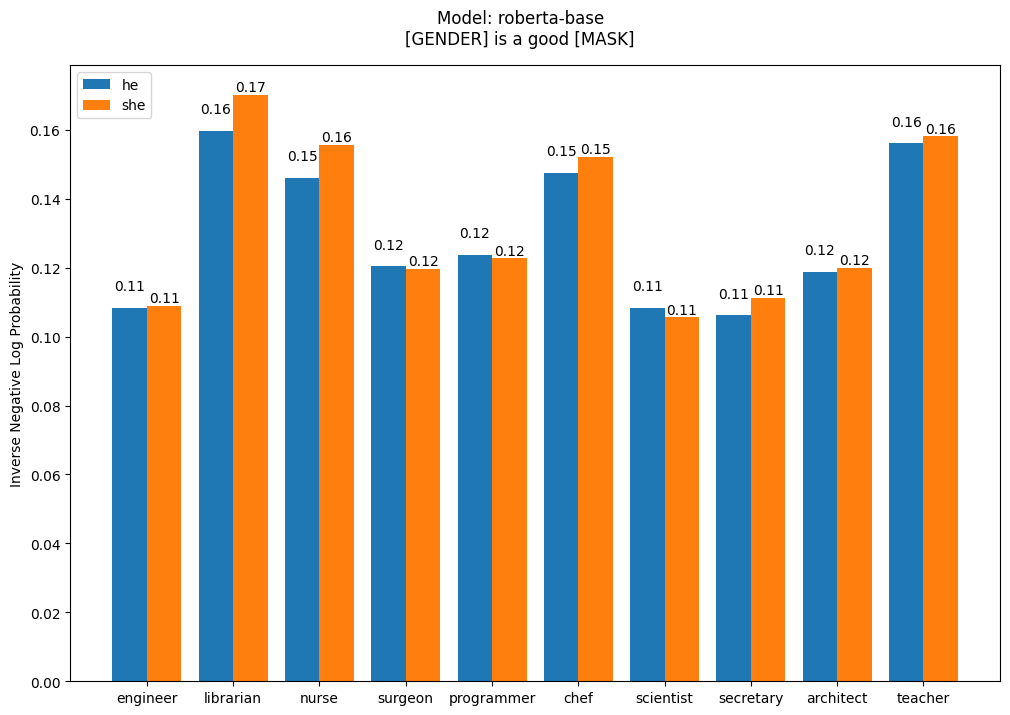

Model used: roberta-large


The specified target token `engineer` does not exist in the model vocabulary. Replacing with `engine`.
The specified target token `librarian` does not exist in the model vocabulary. Replacing with `l`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `n`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `sur`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `program`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `che`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `scient`.
The specified target token `secretary` does not exist in the model vocabulary. Replacing with `secret`.
The specified target token `architect` does not exist in the model vocabulary. Replacing with `arch`.
The specified target token `teacher` does not exist in the model vocabulary. Replacing with 

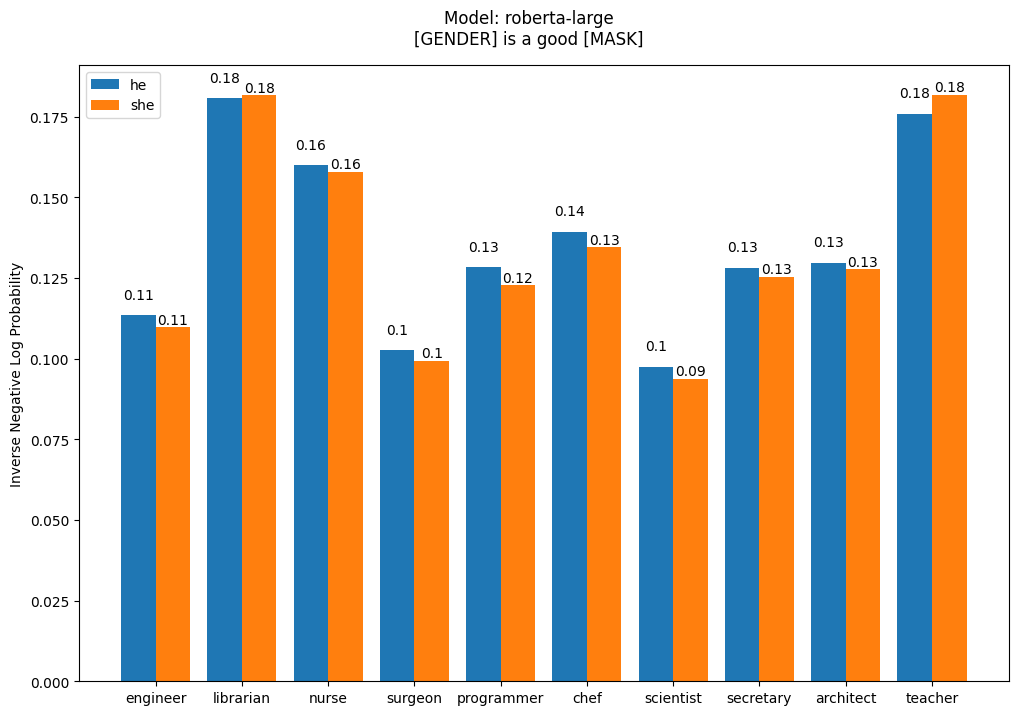

Model used: albert-base-v1


The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `▁programmer`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `▁chef`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `▁scientist`.
The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in th

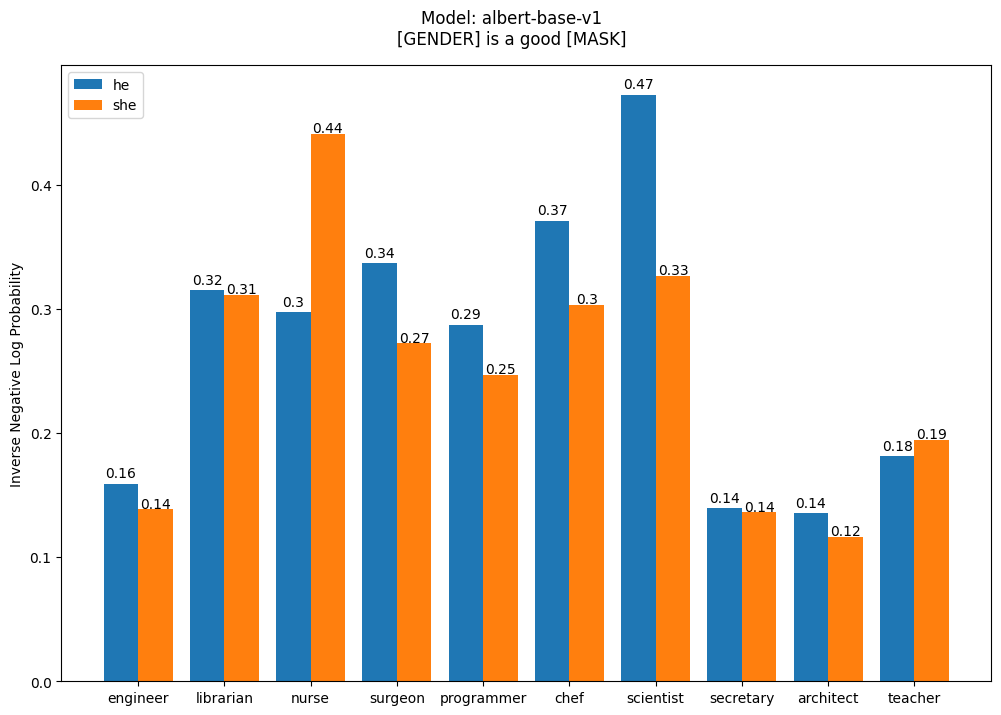

Model used: albert-large-v1


The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `▁programmer`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `▁chef`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `▁scientist`.
The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in th

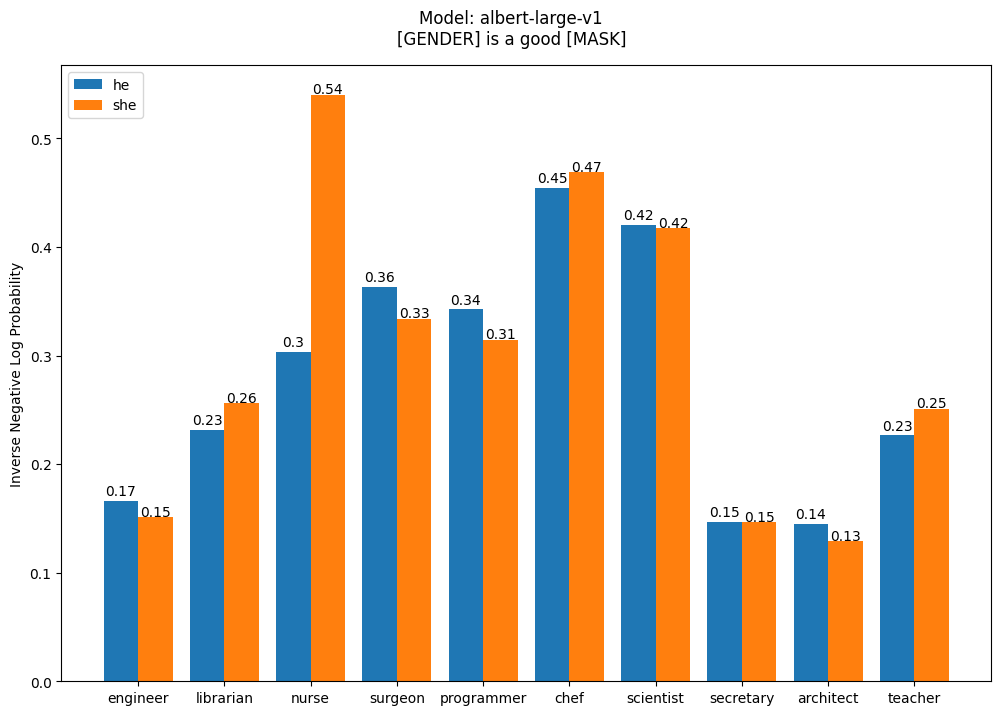

In [ ]:
#Mask Technique 2: Visualizing

models=['bert-base-uncased','bert-large-uncased','distilbert-base-uncased','roberta-base','roberta-large','albert-base-v1','albert-large-v1']

for i in models:
    print(f"Model used: {i}")
    nlp = pipeline("fill-mask", model=i, top_k=10)

    occupations = ['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'chef', 'scientist', 'secretary', 'architect', 'teacher']
    gender = ['he', 'she']
    scores = [[], []]

    for j in gender:
        for occ in occupations:
            output = nlp(f"{j} is a good {nlp.tokenizer.mask_token}.", targets=[occ])
            score = output[0]['score']
            score = (1/(math.log10(score)*(-1)))
            if j == 'he':
                scores[0].append(score)
            else:
                scores[1].append(score)

    fig, ax = plt.subplots(figsize=(12, 8)) # Set the figsize parameter here
    x = np.arange(len(occupations))

    ax.bar(x - 0.2, scores[0], 0.4, label='he')
    ax.bar(x + 0.2, scores[1], 0.4, label='she')

    ax.set_ylabel('Inverse Negative Log Probability')
    fig.suptitle("Model: {}\n[GENDER] is a good [MASK]".format(i), y=0.95)
    ax.set_xticks(x)
    ax.set_xticklabels(occupations)
    ax.legend(loc="upper left")

    for i, v in enumerate(scores[0]):
        ax.text(i - 0.2, v + 0.005, str(round(v, 2)), fontsize=10, color='black', ha='center')
    for i, v in enumerate(scores[1]):
        ax.text(i + 0.2, v + 0.001, str(round(v, 2)), fontsize=10, color='black', ha='center')

    plt.show()

# Predicting both gendered pronoun and occupation - "[MASK] is a good [MASK]"

In [ ]:
#Mask Technique 3


models=['bert-base-uncased','bert-large-uncased','distilbert-base-uncased','roberta-base','roberta-large','albert-base-v1','albert-large-v1']
target_words = [['he', 'she'], ['engineer', 'librarian', 'nurse', 'surgeon', 'programmer', 'chef', 'scientist', 'secretary', 'architect', 'teacher']]

for j in models:
    print(f"Model used: {j}")
    fill_mask = pipeline("fill-mask", model=j, top_k=10)
    sentence = "[MASK1] is a good [MASK2]."
# Loop over each masked token and set target words
    for i, target_words_mask in enumerate(target_words):
        # Predictions for the masked token with target words
        # Input sentence with two masked tokens

        predictions = fill_mask(sentence.replace(f"[MASK{i+1}]", fill_mask.tokenizer.mask_token), targets=target_words_mask)
        
        # Extract predicted token and its score
        print(predictions)
        mask_token = predictions[0]['token_str']
        mask_score = predictions[0]['score']
        
        # Replace the masked token with ,the predicted token in the sentence
        sentence = sentence.replace(f"[MASK{i+1}]", mask_token)
        
        # Print the predicted token and its score
        print("Predicted token for MASK{}: {}".format(i+1, mask_token), "with score:", mask_score)

    # Print the sentence with filled-in words
    print()
    print("Output sentence:", sentence)
    print()

Model used: bert-base-uncased


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


[{'score': 0.034023694694042206, 'token': 2002, 'token_str': 'he', 'sequence': 'he is a good [ mask2 ].'}, {'score': 0.012825102545320988, 'token': 2016, 'token_str': 'she', 'sequence': 'she is a good [ mask2 ].'}]
Predicted token for MASK1: he with score: 0.034023694694042206
[{'score': 0.008162777870893478, 'token': 3836, 'token_str': 'teacher', 'sequence': 'he is a good teacher.'}, {'score': 0.0004082648374605924, 'token': 7155, 'token_str': 'scientist', 'sequence': 'he is a good scientist.'}, {'score': 0.00035246353945694864, 'token': 10026, 'token_str': 'chef', 'sequence': 'he is a good chef.'}, {'score': 0.00030563658219762146, 'token': 9431, 'token_str': 'surgeon', 'sequence': 'he is a good surgeon.'}, {'score': 0.00027110110386274755, 'token': 3992, 'token_str': 'engineer', 'sequence': 'he is a good engineer.'}, {'score': 0.0001677066320553422, 'token': 6821, 'token_str': 'nurse', 'sequence': 'he is a good nurse.'}, {'score': 0.00010653069330146536, 'token': 4944, 'token_str': 

Some weights of the model checkpoint at bert-large-uncased were not used when initializing BertForMaskedLM: ['cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


[{'score': 0.009129396639764309, 'token': 2002, 'token_str': 'he', 'sequence': 'he is a good [ mask2 ].'}, {'score': 0.001055339933373034, 'token': 2016, 'token_str': 'she', 'sequence': 'she is a good [ mask2 ].'}]
Predicted token for MASK1: he with score: 0.009129396639764309
[{'score': 0.01644212380051613, 'token': 3836, 'token_str': 'teacher', 'sequence': 'he is a good teacher.'}, {'score': 0.0008970726630650461, 'token': 7155, 'token_str': 'scientist', 'sequence': 'he is a good scientist.'}, {'score': 0.000538635125849396, 'token': 9431, 'token_str': 'surgeon', 'sequence': 'he is a good surgeon.'}, {'score': 0.00040876035927794874, 'token': 6821, 'token_str': 'nurse', 'sequence': 'he is a good nurse.'}, {'score': 0.0003249381552450359, 'token': 3992, 'token_str': 'engineer', 'sequence': 'he is a good engineer.'}, {'score': 0.0002594967372715473, 'token': 4944, 'token_str': 'architect', 'sequence': 'he is a good architect.'}, {'score': 0.00025230602477677166, 'token': 10026, 'token_

...

[{'score': 0.00013488616968970746, 'token': 700, 'token_str': 'he', 'sequence': 'he is a good [MASK2].'}, {'score': 1.6225310901063494e-05, 'token': 8877, 'token_str': 'she', 'sequence': 'she is a good [MASK2].'}]
Predicted token for MASK1: he with score: 0.00013488616968970746
[{'score': 2.925778744611307e-06, 'token': 462, 'token_str': 'l', 'sequence': 'he is a goodl.'}, {'score': 2.076429609587649e-06, 'token': 859, 'token_str': 'te', 'sequence': 'he is a goodte.'}, {'score': 5.56769634840748e-07, 'token': 282, 'token_str': 'n', 'sequence': 'he is a goodn.'}, {'score': 6.658371631829141e-08, 'token': 2871, 'token_str': 'che', 'sequence': 'he is a goodche.'}, {'score': 1.945324967778106e-08, 'token': 13161, 'token_str': 'arch', 'sequence': 'he is a goodarch.'}, {'score': 1.608283106691033e-08, 'token': 28644, 'token_str': 'program', 'sequence': 'he is a goodprogram.'}, {'score': 1.5835182054502184e-08, 'token': 19301, 'token_str': 'secret', 'sequence': 'he is a goodsecret.'}, {'score

The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `▁programmer`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `▁chef`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `▁scientist`.


[{'score': 1.727771814330481e-05, 'token': 438, 'token_str': 'he', 'sequence': 'he is a good [mask2].'}, {'score': 5.489698196470272e-06, 'token': 1079, 'token_str': 'she', 'sequence': 'she is a good [mask2].'}]
Predicted token for MASK1: he with score: 1.727771814330481e-05
[{'score': 0.0076517704874277115, 'token': 6415, 'token_str': 'scientist', 'sequence': 'he is a good scientist.'}, {'score': 0.002014209982007742, 'token': 8915, 'token_str': 'chef', 'sequence': 'he is a good chef.'}, {'score': 0.0010757747804746032, 'token': 9561, 'token_str': 'surgeon', 'sequence': 'he is a good surgeon.'}, {'score': 0.00067056471016258, 'token': 12793, 'token_str': 'librarian', 'sequence': 'he is a good librarian.'}, {'score': 0.0004312694363761693, 'token': 5425, 'token_str': 'nurse', 'sequence': 'he is a good nurse.'}, {'score': 0.0003277583164162934, 'token': 17968, 'token_str': 'programmer', 'sequence': 'he is a good programmer.'}, {'score': 3.026786998816533e-06, 'token': 14616, 'token_str'

The specified target token `librarian` does not exist in the model vocabulary. Replacing with `▁librarian`.
The specified target token `nurse` does not exist in the model vocabulary. Replacing with `▁nurse`.
The specified target token `surgeon` does not exist in the model vocabulary. Replacing with `▁surgeon`.
The specified target token `programmer` does not exist in the model vocabulary. Replacing with `▁programmer`.
The specified target token `chef` does not exist in the model vocabulary. Replacing with `▁chef`.
The specified target token `scientist` does not exist in the model vocabulary. Replacing with `▁scientist`.


[{'score': 1.939210960699711e-05, 'token': 438, 'token_str': 'he', 'sequence': 'he is a good [mask2].'}, {'score': 1.2193170732643921e-05, 'token': 1079, 'token_str': 'she', 'sequence': 'she is a good [mask2].'}]
Predicted token for MASK1: he with score: 1.939210960699711e-05
[{'score': 0.006283141672611237, 'token': 8915, 'token_str': 'chef', 'sequence': 'he is a good chef.'}, {'score': 0.004168346058577299, 'token': 6415, 'token_str': 'scientist', 'sequence': 'he is a good scientist.'}, {'score': 0.0017646673368290067, 'token': 9561, 'token_str': 'surgeon', 'sequence': 'he is a good surgeon.'}, {'score': 0.0012060462031513453, 'token': 17968, 'token_str': 'programmer', 'sequence': 'he is a good programmer.'}, {'score': 0.0005020910175517201, 'token': 5425, 'token_str': 'nurse', 'sequence': 'he is a good nurse.'}, {'score': 4.783030817634426e-05, 'token': 12793, 'token_str': 'librarian', 'sequence': 'he is a good librarian.'}, {'score': 3.836813266389072e-05, 'token': 14616, 'token_st